# Testes depois do treino 3: fechamento morfológico dos marcadores

**Pergunta:** tapar os buraquinhos do marcador antes do ScribblePrompt, com um **fechamento morfológico** (dilatação seguida de
erosão pelo mesmo disco), deixa o marcador mais fácil de editar por um humano **sem piorar a segmentação**?

- **Fechamento em tons de cinza:** sobre o marcador difuso (valores em [0, 1]), a dilatação é o máximo num disco de raio r px e a
  erosão, o mínimo (Haralick, Sternberg e Zhuang, IEEE TPAMI, 1987). O fechamento nunca diminui o marcador e tapa buracos e
  frestas menores que o disco. Como comuta com a limiarização (Maragos e Schafer, IEEE TASSP, 1987), fechar antes ou depois do
  corte em τ dá o mesmo.
- **Onde entra:** entre a MarkerUNet e o ScribblePrompt, em cada bloco: `MarkerStep → MarkerClosingStep(r) →
  FrozenSegmentationStep(markers_key="markers_closed")`. O marcador cru continua disponível.
- **Sem retreinar:** os modelos dos *folds* de `recortes_negativo`; cada imagem é prevista pelo modelo do *fold* em que ficou de
  fora, limiar 0,5. A inferência é a melhor dos testes anteriores: faixa do negativo 2 px, sobreposição 1/2 e TTA.
- **Raios:** 1, 2, 3 e 5 px, contra o raio 0 (sem fechamento). O diâmetro mediano dos núcleos é ~21 px em 40× e ~12 px em 20×:
  raios grandes podem **unir núcleos vizinhos**, o que também é medido.

Duas tabelas: a **segmentação** (Dice, pareado contra o raio 0) e a **editabilidade do marcador** (componentes, fragmentos, buracos e
como os componentes se distribuem pelas regiões do GT). **Tudo é mostrado no notebook**; salvar é opcional (`SALVAR_RESULTADOS`).
Use um ambiente com **GPU**.

## 0. Setup

In [1]:
import os
import subprocess
import sys

REPO_URL = "https://github.com/Pedro-io/cell-fuzzy-seg.git"
BRANCH = "homolog"


def find_repo_root(start="."):
    p = os.path.abspath(start)
    prev = None
    while p != prev:
        if os.path.isdir(os.path.join(p, "src")) and os.path.exists(os.path.join(p, "pyproject.toml")):
            return p
        prev, p = p, os.path.dirname(p)
    return None


if "google.colab" in sys.modules:
    repo_root = os.path.join("/content", "cell-fuzzy-seg")
    if os.path.exists(repo_root):
        subprocess.run(["git", "-C", repo_root, "fetch", "origin", BRANCH], check=True)
        subprocess.run(["git", "-C", repo_root, "checkout", BRANCH], check=True)
        subprocess.run(["git", "-C", repo_root, "pull", "--ff-only", "origin", BRANCH], check=True)
    else:
        subprocess.run(["git", "clone", "--branch", BRANCH, REPO_URL, repo_root], check=True)
else:
    repo_root = find_repo_root(os.getcwd())
    if repo_root is None:
        raise RuntimeError("Raiz do repositório não encontrada a partir do diretório atual.")

os.chdir(repo_root)
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)
print("Repositório:", repo_root)
print(subprocess.run(["git", "log", "-1", "--oneline"], capture_output=True, text=True).stdout.strip())

Repositório: /content/cell-fuzzy-seg
6c3529e docs(exploracao): saídas dos testes de configurações externas depois do treino


In [2]:
if "google.colab" in sys.modules:
    get_ipython().system("python -m pip install -r requirements.txt -q")
else:
    print("Ambiente local: verifique se as dependências do requirements.txt estão instaladas.")

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.8/60.8 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 213.4/213.4 kB 29.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.8/40.8 MB 22.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.0/15.0 MB 117.7 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 23.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.5/62.5 MB 15.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 20.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 808.6/808.6 kB 67.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 109.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26.5/26.5 MB 100.2 MB/s eta 0:00:0000:0100:01


## 1. Configuração (a mesma do experimento testado)

In [3]:
import json

import matplotlib.pyplot as plt
import numpy as np
import torch

from src.data.load.preprocessed_dataset import NEGATIVE_KEY, load_preprocessed
from src.evaluation.figures import pick_cases, prediction_figure
from src.evaluation.metrics import binary_metrics
from src.evaluation.report import save_run, summarize
from src.losses.loss_composer import LossComposer
from src.losses.terms import DiceTerm
from src.models.configs.marker_unet_config import UNET_CONFIG
from src.models.networks.final_segmentation.scribble_prompting_network import ScribblePromptingNetwork
from src.models.networks.marker_unet import MarkerUNet
from src.pipeline.steps.inference.frozen_segmentation_step import FrozenSegmentationStep
from src.pipeline.steps.inference.marker_step import MarkerStep
from src.pipeline.training_pipeline import TrainingPipeline
from src.pipeline.tiled_pipeline import TiledPipeline
from src.training.checkpoints import fold_name, load_pipeline
from src.training.kfold import TrainConfig, final_epochs, run_kfold

# Experimento cujos modelos são testados: a configuração abaixo precisa ser a dele (a célula seguinte confere).
EXPERIMENT_NAME = "recortes_negativo"
OVERWRITE = False            # recusa gravar por cima de resultados ou modelos que já existem

RGBA_ALPHA = "mask"          # 4º canal da MarkerUNet: máscara do Cellpose ("prob": probabilidade)
TILE_SIZE = 256             # recorte do treino e bloco da avaliação (px da imagem original)
CROPS_PER_IMAGE = 4          # recortes sorteados de cada imagem por época
TILE_OVERLAP = 0.25          # sobreposição dos blocos na avaliação (fração do lado)
SP_INPUT_SIZE = (128, 128)   # entrada do ScribblePrompt (o recorte reduzido)
TAU = 0.5                    # limiar do canal positivo
NEGATIVE_RADIUS = 3              # None: sem negativo; n: negativo = pixels a mais de n px de qualquer máscara do Cellpose

CONFIG = TrainConfig(
    k=5, batch_size=16, max_epochs=200, patience=20, min_delta=0.0,
    lr=1e-4, grad_clip=1.0, threshold=0.5, seed=42, log_every=10,
    crop_size=TILE_SIZE, crops_per_image=CROPS_PER_IMAGE,
)
DESCRIPTION = {
    "perdas": "soft Dice (1,0), sem regularização do marcador",
    "rede_final": f"ScribblePrompt-UNet v1 congelado, scribble_mode=positive, tau={TAU}, input_size={SP_INPUT_SIZE}"
                  + ("" if NEGATIVE_RADIUS is None
                     else f", negativo = fundo do Cellpose (faixa livre de {NEGATIVE_RADIUS} px)"),
    "marker_net": "MarkerUNet (smp Unet, resnet34 ImageNet, 4 canais)",
    "rgba_alpha": RGBA_ALPHA,
    "aumentacao": "rot90 + flips, sorteada a cada época",
    "recortes": f"treino com {CROPS_PER_IMAGE} recortes de {TILE_SIZE}² por imagem por época (MarkerUNet sem redução); avaliação da imagem inteira em blocos de {TILE_SIZE}² com sobreposição {TILE_OVERLAP} e janela de Hann",
}

assert torch.cuda.is_available() or "google.colab" not in sys.modules, "No Colab, use um ambiente com GPU."
print("Device:", CONFIG.device)
print(json.dumps(DESCRIPTION, indent=2, ensure_ascii=False))

Device: cuda
{
  "perdas": "soft Dice (1,0), sem regularização do marcador",
  "rede_final": "ScribblePrompt-UNet v1 congelado, scribble_mode=positive, tau=0.5, input_size=(128, 128), negativo = fundo do Cellpose (faixa livre de 3 px)",
  "marker_net": "MarkerUNet (smp Unet, resnet34 ImageNet, 4 canais)",
  "rgba_alpha": "mask",
  "aumentacao": "rot90 + flips, sorteada a cada época",
  "recortes": "treino com 4 recortes de 256² por imagem por época (MarkerUNet sem redução); avaliação da imagem inteira em blocos de 256² com sobreposição 0.25 e janela de Hann"
}


In [ ]:
import inspect

SALVAR_RESULTADOS = False    # True: grava as tabelas em docs/estudo/resultados/testes_pos_treino_3_<experimento>/
RAIOS_FECHAMENTO = [1, 2, 3, 5]
# Melhor inferência sem retreinar (testes depois do treino 2)
RAIO_NEGATIVO_INFERENCIA = 2
SOBREPOSICAO_INFERENCIA = 0.5
TTA = True
AREA_FRAGMENTO = 20          # componentes do marcador com menos px que isso contam como fragmentos
IMAGENS_20X = {"TCGA-HE-7128-01Z-00-DX1", "TCGA-HE-7129-01Z-00-DX1", "TCGA-HE-7130-01Z-00-DX1"}

if "markers_key" not in inspect.signature(FrozenSegmentationStep.__init__).parameters:
    raise RuntimeError("O src/ carregado é anterior ao fechamento dos marcadores: reinicie a sessão do Colab e rode de novo.")
with open(os.path.join("docs", "estudo", "resultados", EXPERIMENT_NAME, "config.json"), encoding="utf-8") as f:
    REFERENCIA = json.load(f)
if REFERENCIA["descricao"] != DESCRIPTION:
    raise ValueError("A configuração deste notebook não é a do experimento testado; copie-a do notebook dele.")
print(f"Configuração de {EXPERIMENT_NAME} conferida.")

Configuração de recortes_negativo conferida.


## 2. Onde estão os modelos

In [5]:
# Modelos treinados: no Colab, no Google Drive de quem roda o notebook (sobrevive ao fim da sessão); fora dele,
# em ~/cell-fuzzy-models. Troque MODELS_ROOT para gravar em outro lugar.
if "google.colab" in sys.modules:
    try:
        from google.colab import drive

        drive.mount("/content/drive")
        MODELS_ROOT = "/content/drive/MyDrive/cell-fuzzy-models"
    except Exception as erro:
        print(f"Drive não montado ({erro}): os modelos ficam no disco da sessão e somem quando ela terminar.")
        MODELS_ROOT = "/content/cell-fuzzy-models"
else:
    MODELS_ROOT = os.path.expanduser(os.path.join("~", "cell-fuzzy-models"))
MODELS_DIR = os.path.join(MODELS_ROOT, EXPERIMENT_NAME)
print("Modelos em:", MODELS_DIR)

Mounted at /content/drive
Modelos em: /content/drive/MyDrive/cell-fuzzy-models/recortes_negativo


## 3. Dados de treino

In [6]:
train_samples = load_preprocessed("train", alpha=RGBA_ALPHA, negative_radius=NEGATIVE_RADIUS)
TRAIN_IDS = sorted(train_samples)
print(f"Treino: {len(train_samples)} imagens (o teste não é carregado neste notebook)")

d = [binary_metrics(s["cellpose_segmentation"] > 0, s["ground_truth"])["dice"] for s in train_samples.values()]
print(f"Cellpose sozinho, treino: Dice {np.mean(d):.4f} ± {np.std(d, ddof=1):.4f}")

Treino: 37 imagens (o teste não é carregado neste notebook)
Cellpose sozinho, treino: Dice 0.8450 ± 0.0302


## 4. Rede final e montagem do experimento

In [7]:
checkpoint = ScribblePromptingNetwork.download_checkpoint(os.path.join(MODELS_ROOT, "scribbleprompt"))
FINAL_NET = ScribblePromptingNetwork(
    checkpoint=checkpoint, device=CONFIG.device, scribble_mode="positive",
    positive_threshold=TAU, input_size=SP_INPUT_SIZE,
)


def factory():
    """Monta um experimento novo: MarkerUNet recém-inicializada, pipeline em blocos e perdas.

    O treino passa recortes de TILE_SIZE² (a MarkerUNet os vê sem redução); a avaliação passa a imagem
    inteira, que o TiledPipeline divide em blocos de TILE_SIZE² e cola de volta. O ScribblePrompt é
    congelado e não guarda estado, então a mesma instância serve a todos os folds.
    """
    marker_net = MarkerUNet(config=UNET_CONFIG)
    pipeline = TrainingPipeline([
        MarkerStep(model=marker_net, differentiable=True, target_size=TILE_SIZE, device=CONFIG.device),
        FrozenSegmentationStep(final_network=FINAL_NET, device=CONFIG.device,
                               negative_key=None if NEGATIVE_RADIUS is None else NEGATIVE_KEY),
    ])
    composer = LossComposer([DiceTerm()])
    return marker_net, TiledPipeline(pipeline, tile_size=TILE_SIZE, overlap=TILE_OVERLAP), composer

## 5. Modelos dos *folds*, pipelines com fechamento e métricas

`com_fechamento` remonta o pipeline de cada *fold* com o passo do fechamento entre a MarkerUNet e o ScribblePrompt (a MarkerUNet é
a mesma, já treinada). `editabilidade` mede o marcador cortado em τ (o que o ScribblePrompt recebe como scribble):

- **componentes** (8-vizinhança) e **fragmentos** (componentes com menos de `AREA_FRAGMENTO` px);
- **buracos**: regiões sem marcador cercadas por marcador (4-vizinhança, sem tocar a borda da imagem);
- pelas **regiões do GT** (o GT é binário: núcleos que se tocam formam uma região só): fração das regiões **sem marcador**, com
  **um** componente e **partidas** (dois ou mais componentes); e componentes que **unem** duas ou mais regiões ou que caem **fora**
  do GT.

In [8]:
import time
from collections import Counter

import pandas as pd
from scipy import ndimage
from scipy.stats import wilcoxon

from src.data.load.preprocessed_dataset import PreprocessedDataset, cellpose_negative, collate_samples
from src.evaluation.report import provenance
from src.pipeline.steps.inference.marker_closing_step import MarkerClosingStep, grey_closing

FOLDS = []
for k in range(CONFIG.k):
    pipeline, meta = load_pipeline(factory, MODELS_DIR, fold_name(k))
    FOLDS.append((k, pipeline, meta["val_ids"]))
print({k: len(ids) for k, _, ids in FOLDS}, "imagens de validação por fold")

AMOSTRAS = {i: {**s, NEGATIVE_KEY: cellpose_negative(s["cellpose_segmentation"], RAIO_NEGATIVO_INFERENCIA)}
            for i, s in train_samples.items()}


def com_fechamento(tiled, raio, overlap=SOBREPOSICAO_INFERENCIA):
    """O pipeline do fold com o fechamento de raio `raio` antes do ScribblePrompt (raio 0: sem fechamento)."""
    passos = [tiled.pipeline.steps[0]]
    if raio > 0:
        passos.append(MarkerClosingStep(radius=raio))
    passos.append(FrozenSegmentationStep(final_network=FINAL_NET, device=CONFIG.device, negative_key=NEGATIVE_KEY,
                                         markers_key="markers_closed" if raio > 0 else "markers"))
    return TiledPipeline(TrainingPipeline(passos), tile_size=tiled.tile_size, overlap=overlap)


def lote(amostras, image_id):
    batch = collate_samples([PreprocessedDataset(amostras, ids=[image_id])[0]])
    return {c: (v.to(CONFIG.device) if torch.is_tensor(v) else v) for c, v in batch.items()}


def rodar(tiled, batch, tta):
    """Probabilidade (H, W) e marcador cru (H, W); com TTA, a probabilidade é a média das 8 rotações e espelhamentos."""
    with torch.no_grad():
        saida = tiled.run(batch, verbose=False)
        prob, marcador = saida["segmentation"], saida["markers"]
        if tta:
            for k in range(4):
                for espelhar in (False, True):
                    if k == 0 and not espelhar:
                        continue
                    def ida(x):
                        if not (torch.is_tensor(x) and x.ndim == 4):
                            return x
                        x = torch.rot90(x, k, dims=(-2, -1))
                        return torch.flip(x, dims=(-1,)) if espelhar else x
                    s = tiled.run({c: ida(v) for c, v in batch.items()}, verbose=False)["segmentation"]
                    if espelhar:
                        s = torch.flip(s, dims=(-1,))
                    prob = prob + torch.rot90(s, -k, dims=(-2, -1))
            prob = prob / 8
    return prob[0, 0].float().cpu().numpy(), marcador[0, 0].float().cpu().numpy()


def editabilidade(marcador, gt, tau=TAU):
    m = marcador > tau
    rotulos, n = ndimage.label(m, structure=np.ones((3, 3)))
    areas = ndimage.sum(m, rotulos, range(1, n + 1)) if n else np.zeros(0)
    fundo, n_fundo = ndimage.label(~m)
    na_borda = set(np.unique(np.concatenate([fundo[0], fundo[-1], fundo[:, 0], fundo[:, -1]]))) - {0}
    regioes, n_gt = ndimage.label(gt > 0)
    dentro = (rotulos > 0) & (regioes > 0)
    pares = np.unique(np.stack([rotulos[dentro], regioes[dentro]]), axis=1) if dentro.any() else np.zeros((2, 0), int)
    comps_por_regiao = Counter(pares[1].tolist())
    regioes_por_comp = Counter(pares[0].tolist())
    return {"componentes": n, "fragmentos": int((areas < AREA_FRAGMENTO).sum()), "buracos": n_fundo - len(na_borda),
            "regioes_sem_marcador": 1 - len(comps_por_regiao) / max(n_gt, 1),
            "regioes_um_componente": sum(v == 1 for v in comps_por_regiao.values()) / max(n_gt, 1),
            "regioes_partidas": sum(v >= 2 for v in comps_por_regiao.values()) / max(n_gt, 1),
            "componentes_unindo": sum(v >= 2 for v in regioes_por_comp.values()),
            "componentes_fora": n - len(regioes_por_comp)}


def avaliar(condicao, raio, amostras=AMOSTRAS, overlap=SOBREPOSICAO_INFERENCIA, tta=TTA):
    linhas, marcadores = [], {}
    for k, tiled, val_ids in FOLDS:
        tiled = com_fechamento(tiled, raio, overlap)
        for image_id in val_ids:
            prob, marcadores[image_id] = rodar(tiled, lote(amostras, image_id), tta)
            s = amostras[image_id]
            base = binary_metrics(s["cellpose_segmentation"] > 0, s["ground_truth"])
            linhas.append({"condicao": condicao, "raio": raio, "id": image_id, "fold": k,
                           "aumento_20x": image_id in IMAGENS_20X, **binary_metrics(prob, s["ground_truth"]),
                           **{f"cellpose_{m}": v for m, v in base.items()}})
    return linhas, marcadores

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

{0: 8, 1: 8, 2: 7, 3: 7, 4: 7} imagens de validação por fold


## 6. Segmentação

Duas linhas de referência: o pipeline **como foi treinado** (faixa 3 px, sobreposição 1/4, sem TTA; precisa dar o Dice registrado) e a
**melhor inferência sem fechamento** (raio 0), contra a qual cada raio é comparado.

In [9]:
inicio = time.time()
LINHAS, _ = avaliar("como foi treinado", 0, amostras=train_samples, overlap=TILE_OVERLAP, tta=False)
linhas, MARCADORES = avaliar("fechamento 0 (melhor inferência)", 0)
LINHAS += linhas
for r in RAIOS_FECHAMENTO:
    LINHAS += avaliar(f"fechamento {r} px", r)[0]
df = pd.DataFrame(LINHAS)
print(f"{(time.time() - inicio) / 60:.1f} min")

registro = pd.read_csv(os.path.join("docs", "estudo", "resultados", EXPERIMENT_NAME, "folds.csv"))
print(f"Dice registrado de {EXPERIMENT_NAME}: {registro.dice.mean():.4f} | como foi treinado agora: "
      f"{df[df.condicao == 'como foi treinado'].dice.mean():.4f}")
print(f"Cellpose: Dice {df[df.condicao == 'como foi treinado'].cellpose_dice.mean():.4f}")

REFERENCIA_CONDICAO = "fechamento 0 (melhor inferência)"


def comparar(df):
    ref = df[df.condicao == REFERENCIA_CONDICAO].set_index("id")
    tabela = []
    for condicao in dict.fromkeys(df.condicao):
        s = df[df.condicao == condicao].set_index("id").loc[ref.index]
        d = s.dice - ref.dice
        p = wilcoxon(s.dice, ref.dice).pvalue if (d != 0).any() else float("nan")
        tabela.append({"condição": condicao, "Dice": s.dice.mean(), "precisão": s.precision.mean(),
                       "revocação": s.recall.mean(), "massa": s.mass_ratio.mean(), "Δ raio 0": d.mean(),
                       "melhora/piora": f"{int((d > 0).sum())}/{int((d < 0).sum())}", "p": p,
                       "acima do Cellpose": int((s.dice > s.cellpose_dice).sum()), "Dice 20×": s[s.aumento_20x].dice.mean()})
    return pd.DataFrame(tabela)


pd.set_option("display.width", 220)
tabela = comparar(df)
tabela.round(4)

18.7 min
Dice registrado de recortes_negativo: 0.8350 | como foi treinado agora: 0.8350
Cellpose: Dice 0.8450


,condição,Dice,precisão,revocação,massa,Δ raio 0,melhora/piora,p,acima do Cellpose,Dice 20×
0,como foi treinado,0.8350,0.8116,0.8637,1.0695,-0.0072,4/33,0.0000,7,0.8095
1,fechamento 0 (melhor inferência),0.8423,0.8395,0.8482,1.0142,0.0000,0/0,NaN,11,0.8266
2,fechamento 1 px,0.8425,0.8317,0.8567,1.0339,0.0002,22/15,0.4111,9,0.8260
3,fechamento 2 px,0.8421,0.8242,0.8640,1.0525,-0.0002,17/20,0.7542,9,0.8244
4,fechamento 3 px,0.8416,0.8208,0.8667,1.0602,-0.0006,14/23,0.2486,10,0.8237
5,fechamento 5 px,0.8381,0.8049,0.8775,1.0949,-0.0042,10/27,0.0011,8,0.8184


### Como ler a tabela acima

- **como foi treinado:** conferência; tem de dar o Dice registrado na validação cruzada (0,835).
- **fechamento 0 (melhor inferência):** a referência das comparações (faixa 2 px, sobreposição 1/2, TTA; deu 0,8423 nos testes
  anteriores).
- **Δ raio 0, melhora/piora, p:** diferença média imagem por imagem contra o raio 0, quantas imagens melhoram e pioram e o
  Wilcoxon pareado. Para a contribuição de editabilidade, o que importa é o fechamento **não piorar** o Dice (Δ perto de zero).
- **massa:** previsto / GT; se subir com o raio, o fechamento está inchando a segmentação (ou unindo núcleos).

## 7. Editabilidade do marcador

Mesmos marcadores crus (a MarkerUNet não muda com o raio), fechados na imagem inteira e cortados em τ. Médias por imagem nas 37.

In [10]:
EDIT = []
for image_id, marcador in MARCADORES.items():
    gt = train_samples[image_id]["ground_truth"]
    for r in [0] + RAIOS_FECHAMENTO:
        fechado = marcador if r == 0 else grey_closing(torch.from_numpy(marcador), r).numpy()
        EDIT.append({"raio": r, "id": image_id, "aumento_20x": image_id in IMAGENS_20X, **editabilidade(fechado, gt)})
edit = pd.DataFrame(EDIT)
resumo_edit = edit.drop(columns=["id", "aumento_20x"]).groupby("raio").mean()
resumo_edit.round(3)

,componentes,fragmentos,buracos,regioes_sem_marcador,regioes_um_componente,regioes_partidas,componentes_unindo,componentes_fora
raio,,,,,,,,
0,2745.757,2027.514,1051.568,0.019,0.182,0.800,20.703,640.027
1,1543.649,878.216,376.919,0.019,0.461,0.520,22.946,428.811
2,938.459,312.703,161.351,0.019,0.811,0.171,29.216,309.568
3,800.486,231.216,17.919,0.019,0.895,0.086,46.622,272.892
5,510.243,141.703,13.243,0.018,0.956,0.026,87.568,174.270


### Como ler a tabela acima

Cada linha é um raio (0 = marcador sem fechamento); os valores são médias por imagem.

- **componentes, fragmentos, buracos:** quanto menos, mais limpo o marcador para quem vai editá-lo. Se os buracos já forem poucos no
  raio 0, o fechamento quase não tem o que tapar.
- **regioes_um_componente:** fração das regiões do GT com exatamente um componente de marcador, o caso ideal para editar (um
  traço por núcleo). **regioes_partidas** deve cair com o fechamento; **regioes_sem_marcador** não muda (o fechamento não cria
  marcador longe de outro).
- **componentes_unindo:** componentes que tocam duas ou mais regiões do GT. É o custo do fechamento: se subir muito com o raio,
  ele está colando núcleos vizinhos. **componentes_fora:** componentes que não tocam o GT.

## 8. Figura: marcador cru e fechado

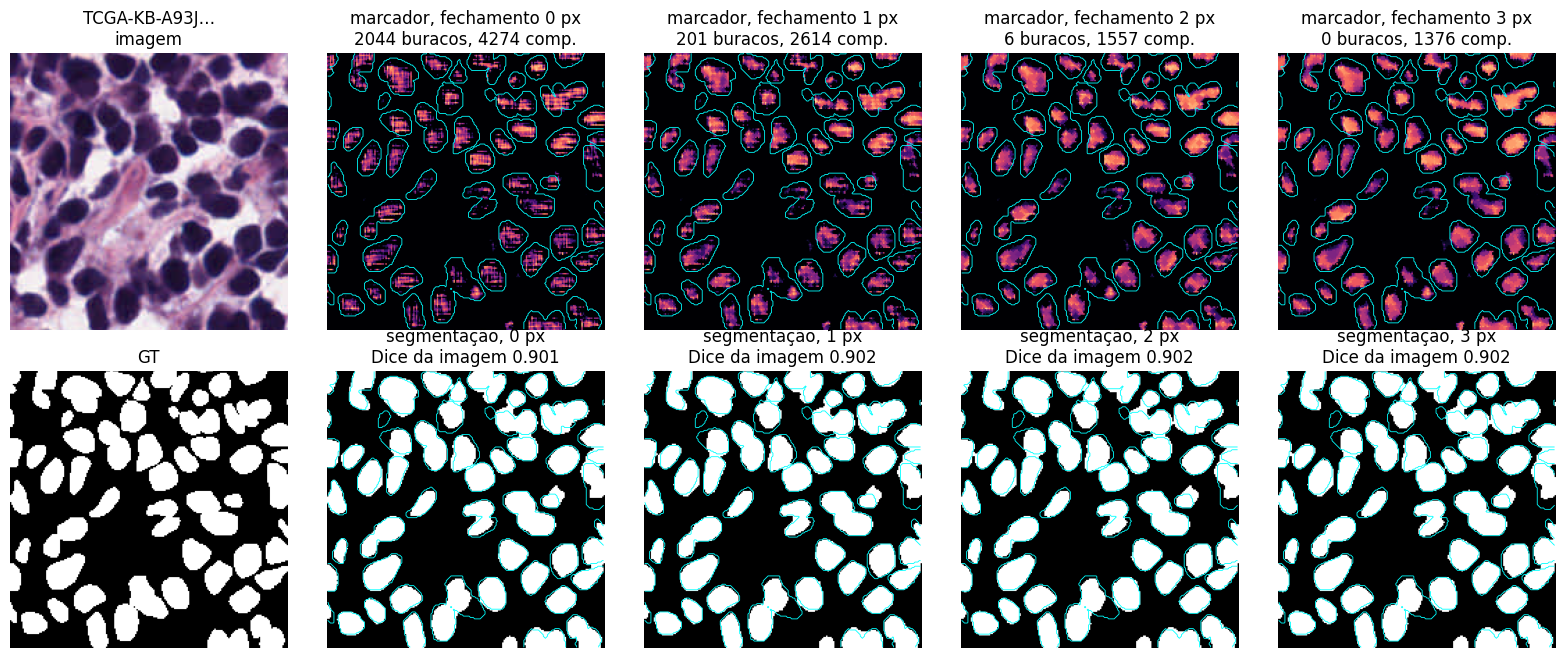

In [11]:
buracos0 = edit[edit.raio == 0].set_index("id").buracos
FIG_ID = buracos0.idxmax()
marcador = MARCADORES[FIG_ID]
m = marcador > TAU
fundo, _ = ndimage.label(~m)
na_borda = set(np.unique(np.concatenate([fundo[0], fundo[-1], fundo[:, 0], fundo[:, -1]])))
ys, xs = np.nonzero(~np.isin(fundo, list(na_borda)) & (fundo > 0))
LADO = 200
cy = int(np.median(ys)) if len(ys) else marcador.shape[0] // 2
cx = int(np.median(xs)) if len(xs) else marcador.shape[1] // 2
y0 = int(np.clip(cy - LADO // 2, 0, marcador.shape[0] - LADO))
x0 = int(np.clip(cx - LADO // 2, 0, marcador.shape[1] - LADO))
janela = (slice(y0, y0 + LADO), slice(x0, x0 + LADO))
s = train_samples[FIG_ID]
gt = s["ground_truth"][janela] > 0
raios = [0] + [r for r in RAIOS_FECHAMENTO if r <= 3]
k, tiled, _ = next(f for f in FOLDS if FIG_ID in f[2])

fig, eixos = plt.subplots(2, len(raios) + 1, figsize=(3.2 * (len(raios) + 1), 6.6))
eixos[0, 0].imshow(s["image"][janela])
eixos[0, 0].set_title(f"{FIG_ID[:12]}…\nimagem")
eixos[1, 0].imshow(gt, cmap="gray")
eixos[1, 0].set_title("GT")
for j, r in enumerate(raios, start=1):
    fechado = marcador if r == 0 else grey_closing(torch.from_numpy(marcador), r).numpy()
    corte = np.clip((fechado - TAU) / (1 - TAU), 0, 1)
    eixos[0, j].imshow(corte[janela], cmap="magma", vmin=0, vmax=1)
    eixos[0, j].contour(gt, levels=[0.5], colors="cyan", linewidths=0.6)
    e = editabilidade(fechado, s["ground_truth"])
    eixos[0, j].set_title(f"marcador, fechamento {r} px\n{e['buracos']} buracos, {e['componentes']} comp.")
    prob, _ = rodar(com_fechamento(tiled, r), lote(AMOSTRAS, FIG_ID), TTA)
    d = binary_metrics(prob, s["ground_truth"])["dice"]
    eixos[1, j].imshow(prob[janela] > 0.5, cmap="gray")
    eixos[1, j].contour(gt, levels=[0.5], colors="cyan", linewidths=0.6)
    eixos[1, j].set_title(f"segmentação, {r} px\nDice da imagem {d:.3f}")
for eixo in eixos.ravel():
    eixo.axis("off")
plt.tight_layout()
plt.show()

### Como ler a figura acima

A imagem é a de **mais buracos** no marcador sem fechamento, recortada em 200 × 200 px em volta dos buracos.

- **Linha de cima:** o marcador **cortado em τ** (o scribble que o ScribblePrompt recebe), em escala fixa de 0 (preto) a 1 (amarelo
  claro), com o contorno do GT em ciano. Da esquerda para a direita: sem fechamento e com fechamento de 1, 2 e 3 px. O título conta
  buracos e componentes da imagem inteira.
- **Linha de baixo:** a segmentação final (probabilidade > 0,5) com cada raio, com o contorno do GT, e o Dice da imagem inteira.

O que procurar: os buracos sumindo na linha de cima sem que marcadores de núcleos vizinhos se colem, e a linha de baixo quase igual.

## 9. Salvar (opcional)

In [ ]:
if SALVAR_RESULTADOS:
    pasta = os.path.join("docs", "estudo", "resultados", f"testes_pos_treino_3_{EXPERIMENT_NAME}")
    os.makedirs(pasta, exist_ok=False)
    df.to_csv(os.path.join(pasta, "por_imagem.csv"), index=False)
    tabela.to_csv(os.path.join(pasta, "resumo.csv"), index=False)
    edit.to_csv(os.path.join(pasta, "editabilidade_por_imagem.csv"), index=False)
    resumo_edit.to_csv(os.path.join(pasta, "editabilidade_resumo.csv"))
    with open(os.path.join(pasta, "config.json"), "w", encoding="utf-8") as f:
        json.dump({"experimento": EXPERIMENT_NAME, "raios_fechamento": RAIOS_FECHAMENTO,
                   "raio_negativo_inferencia": RAIO_NEGATIVO_INFERENCIA, "sobreposicao_inferencia": SOBREPOSICAO_INFERENCIA,
                   "tta": TTA, "area_fragmento": AREA_FRAGMENTO, "procedencia": provenance()}, f, indent=2, ensure_ascii=False)
    print("Resultados em:", pasta)
else:
    print("Nada salvo (SALVAR_RESULTADOS = False).")